YOU MUST STILL FILL IN THfE FOLLOWING VARIABLES:
VARIABLES START


varyingVariable,
hasBottail,
obtaining_motor_csv,
numberSims,
processes,
latitude,
longitude,
elevation,
atmosphere_type,
env_file,
fahrenheit_temp,
pressure,
wind_u,
wind_v,
date,
generatedFilesLocation,
dryMotorMass,
propellant_mass,
grainInnerRadius,
grainOuterRadius,
grainHeight,
the_nozzle_radius,
the_throat_radius,
the_nozzle_position,
grain_center_of_mass_position,
center_of_dry_mass_within_motor,
motor_thrust_file,
burn_time,
numGrains,
grainSeparation,
the_motor_position,
the_center_of_mass_without_motor,
rocket_center_of_dry_mass_position,
power_off_file,
power_on_file,
inclination,
heading,
rail_length,
using-airbrakes,
doing_monte_carlo,


VARIABLES END


Impulse is: 9680.79964519286
TOTAL SIMS IS: 30


'Completed 30 iterations successfully. Total CPU time: 1.40625 s. Total wall time: 1.4670851230621338 s'

Thrust source: [[0, 0], [0.007, 258.8019], [0.014, 370.0942], [0.021, 598.0513], [0.027, 1169.3671], [0.034, 2020.1744], [0.041, 2666.7934], [0.048, 2763.4627], [0.054, 2546.3848], [0.061, 2622.8263], [0.068, 2870.2982], [0.075, 2943.9553], [0.081, 2952.9856], [0.088, 2980.0242], [0.095, 3005.8235], [0.102, 3023.4051], [0.108, 3088.3008], [0.115, 3141.5713], [0.122, 3154.2436], [0.129, 3155.3105], [0.135, 3178.2182], [0.142, 3173.2007], [0.149, 3179.5166], [0.156, 3195.8997], [0.162, 3207.7366], [0.169, 3214.5788], [0.176, 3225.1015], [0.183, 3238.5685], [0.189, 3255.8083], [0.196, 3267.7081], [0.203, 3273.032], [0.21, 3278.7656], [0.216, 3283.0348], [0.223, 3283.6501], [0.23, 3291.8962], [0.237, 3295.4697], [0.243, 3303.8069], [0.25, 3313.5676], [0.257, 3321.7786], [0.264, 3327.4037], [0.27, 3334.6124], [0.277, 3339.2852], [0.284, 3349.8045], [0.291, 3364.8048], [0.297, 3364.1063], [0.304, 3372.6825], [0.311, 3371.4086], [0.318, 3385.8826], [0.324, 3398.9623], [0.331, 3407.1768], [0.3

C:\Users\mahd\Documents\SimulationRocketPy\rocketpy_repo\rocketpy\mathutils\_calc\polation_1d.py:119: RuntimeWarning: divide by zero encountered in divide
  self._slopes = np.diff(self._y) / np.diff(self._x)


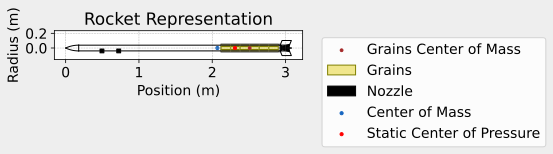

Center of mass without motor is currently set to: 1.8
printing ts crack


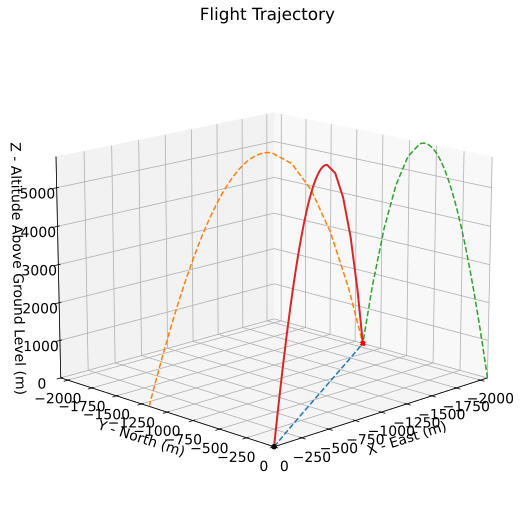


Initial Conditions

Initial time: 0.000 s
Position - x: 0.00 m | y: 0.00 m | z: 750.00 m
Velocity - Vx: 0.00 m/s | Vy: 0.00 m/s | Vz: 0.00 m/s
Attitude (quaternions) - e0: 0.865 | e1: 0.045 | e2: -0.026 | e3: -0.499
Euler Angles - Spin φ : -180.00° | Nutation θ: -6.00° | Precession ψ: 120.00°
Angular Velocity - ω1: 0.00 rad/s | ω2: 0.00 rad/s | ω3: 0.00 rad/s
Initial Stability Margin: 3.042 c


Surface Wind Conditions

Frontal Surface Wind Speed: -0.00 m/s
Lateral Surface Wind Speed: 0.00 m/s


Launch Rail

Launch Rail Length: 7.096 m
Launch Rail Inclination: 84.00°
Launch Rail Heading: 240.00°


Rail Departure State

Rail Departure Time: 0.306 s
Rail Departure Velocity: 34.083 m/s
Rail Departure Stability Margin: 3.141 c
Rail Departure Angle of Attack: 0.000°
Rail Departure Thrust-Weight Ratio: 14.604
Rail Departure Reynolds Number: 1.732e+05


Burn out State

Burn out time: 3.350 s
Altitude at burn out: 1498.959 m (ASL) | 748.959 m (AGL)
Rocket speed at burn out: 385.468 m/s
Freestr

In [1]:
from time import process_time, time
from Helpers.ConcurrentFunctions import RunFlightWithMonteCarlo
from IPython.display import display
from scipy.stats import norm
from rocketpy import Environment
import datetime

#Calculate and plot landing elipses
# Import libraries

from Helpers import FlightParams
from Helpers.Wind import MakeWind

%config InlineBackend.figure_formats = ['svg']
import matplotlib as mpl
import matplotlib.pyplot as plt


%matplotlib inline
mpl.rcParams["figure.figsize"] = [8, 5]
mpl.rcParams["figure.dpi"] = 120
mpl.rcParams["font.size"] = 14
mpl.rcParams["legend.fontsize"] = 14
mpl.rcParams["figure.titlesize"] = 14


import logging
import numpy as np

# M1850W.all_info()

#sets up the ability to log inputs.
def setup_logging():
    class MyHandler(logging.FileHandler):
        def emit(self, record):
            super().emit(record)  # Call the superclass's emit method
            self.flush()  # Flush after each log message

    # Use your custom handler
    logger = logging.getLogger()
    logger.setLevel(logging.INFO)
    handler = MyHandler('app.log', 'a')
    formatter = logging.Formatter('%(asctime)s - %(levelname)s - %(message)s')
    handler.setFormatter(formatter)
    logger.addHandler(handler)

resultsFile = open(FlightParams.Parameters["generatedFilesLocation"] + "results.txt", "w")

# envParams["env_file"] = row[0].value

print("TOTAL SIMS IS: " + str(FlightParams.Parameters["numberSims"]))
resultsFile.write("TOTAL SIMS IS: " + str(FlightParams.Parameters["numberSims"]) + "\n\n\n")
    
setup_logging()
# env.all_info()
# Create data files for inputs, outputs and error logging
filename = "MonteCarlo1"
MonteCarloErrorFile = open("../Output/" + str(filename) + ".Errors.txt", "w")
MonteCarloInputFile = open("../Output/" + str(filename) + ".Input.txt", "w")
MonteCarloOutputFile = open("../Output/" + str(filename) + ".Output.txt", "w")

initial_wall_time = time()
initial_cpu_time = process_time()
# Iterate over flight settings
out = display("Starting", display_id=True)
number_of_simulations = FlightParams.Parameters["numberSims"]
totalProcesses = FlightParams.Parameters["processes"]
simsPerProcess = number_of_simulations / totalProcesses

theDate = datetime.date.today()
theDate = [theDate.year, theDate.month, theDate.day, 12]

RunFlightWithMonteCarlo(1, initial_cpu_time, False, theDate)


## Print and save total time
final_string = f"Completed {number_of_simulations} iterations successfully. Total CPU time: {process_time() - initial_cpu_time} s. Total wall time: {time() - initial_wall_time} s"
resultsFile.write(f"Completed {number_of_simulations} iterations successfully. Total CPU time: {process_time() - initial_cpu_time} s. Total wall time: {time() - initial_wall_time} s\n")
out.update(final_string)
MonteCarloInputFile.write(final_string + "\n")
MonteCarloOutputFile.write(final_string + "\n")
MonteCarloErrorFile.write(final_string + "\n")

## Close files
MonteCarloInputFile.close()
MonteCarloOutputFile.close()
MonteCarloErrorFile.close()

# Initialize variable to store all results
dispersion_general_results = []

dispersion_results = {
    "out_of_rail_time": [],
    "out_of_rail_velocity": [],
    "apogee_time": [],
    "apogee_altitude": [],
    "apogee_x": [],
    "apogee_y": [],
    "impact_x": [],
    "impact_y": [],
    "initial_static_margin": [],
    "out_of_rail_static_margin": [],
    "out_of_rail_stability_margin": [],
    "max_velocity": [],
    "execution_time": [],
}

# Get all dispersion results
# Get file
dispersion_output_file = open("../Output/" + str(filename) + ".Output.txt", "r+")

# Read each line of the file and convert to dict
for line in dispersion_output_file:
    # Skip comments lines
    if line[0] != "{":
        continue
    # Eval results and store them
    flight_result = eval(line)
    dispersion_general_results.append(flight_result)
    for parameter_key, parameter_value in flight_result.items():
        dispersion_results[parameter_key].append(parameter_value)

# Close data file
dispersion_output_file.close()

# Print number of flights simulated
N = len(dispersion_general_results)
print("Number of simulations: ", N)
resultsFile.write("Number of simulations: " + str(N) + "\n")

# Retrieve dispersion data por apogee and impact XY position
apogee_x = np.array(dispersion_results["apogee_x"])
apogee_y = np.array(dispersion_results["apogee_y"])

resultsFile.close()